In [1]:
import pandas as pd

df = pd.read_csv("donnees_analyse/retards_hdf.csv", sep=";")

In [2]:
df.shape


(73308, 23)

In [3]:
df.dtypes

trip_id              object
numero_train        float64
date_service          int64
ligne                object
nom_ligne            object
stop_id              object
gare                 object
hauts_de_france       int64
latitude            float64
longitude           float64
ordre_arret         float64
heure_prevue         object
retard_secondes       int64
retard_minutes      float64
en_retard             int64
statut_train         object
statut_arret         object
type_observation     object
pluie_mm            float64
neige_cm            float64
temperature         float64
vent_kmh            float64
rafales_kmh         float64
dtype: object

In [4]:
df.head()

,trip_id,numero_train,date_service,ligne,nom_ligne,stop_id,gare,hauts_de_france,latitude,longitude,...,retard_minutes,en_retard,statut_train,statut_arret,type_observation,pluie_mm,neige_cm,temperature,vent_kmh,rafales_kmh
0,OCESN9864F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,30.0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
1,OCESN9868F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,30.0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
2,OCESN9836F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0.0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
3,OCESN839172F1187_F:TER:FR:Line::9d60af5b-0820-...,839172.0,20261008,K1,PARIS - STRASBOURG,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,5.0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
4,OCESN839171F1187_F:TER:FR:Line::9d60af5b-0820-...,NaN,20261008,NaN,NaN,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,0.0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN


In [5]:
df.head()

,trip_id,numero_train,date_service,ligne,nom_ligne,stop_id,gare,hauts_de_france,latitude,longitude,...,retard_minutes,en_retard,statut_train,statut_arret,type_observation,pluie_mm,neige_cm,temperature,vent_kmh,rafales_kmh
0,OCESN9864F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,30.0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
1,OCESN9868F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,30.0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
2,OCESN9836F1187_F:OUI:FR:Line::A6C76228-9224-4C...,NaN,20261008,NaN,NaN,StopPoint:OCETGV INOUI-87223263,Lille Europe,1,50.63940,3.075721,...,0.0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
3,OCESN839172F1187_F:TER:FR:Line::9d60af5b-0820-...,839172.0,20261008,K1,PARIS - STRASBOURG,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,5.0,1,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN
4,OCESN839171F1187_F:TER:FR:Line::9d60af5b-0820-...,NaN,20261008,NaN,NaN,StopPoint:OCETrain TER-87116582,Château-Thierry,1,49.03814,3.409302,...,0.0,0,PREVU,PREVU,CONSTATE,NaN,NaN,NaN,NaN,NaN


In [6]:
(df.isna().mean() * 100).round(1).sort_values(ascending=False)

rafales_kmh         6.8
vent_kmh            6.8
temperature         6.8
neige_cm            6.8
pluie_mm            6.8
ordre_arret         6.6
heure_prevue        6.6
numero_train        6.5
nom_ligne           6.5
ligne               6.5
hauts_de_france     0.0
latitude            0.0
longitude           0.0
gare                0.0
retard_secondes     0.0
retard_minutes      0.0
en_retard           0.0
statut_train        0.0
statut_arret        0.0
type_observation    0.0
stop_id             0.0
date_service        0.0
trip_id             0.0
dtype: float64

In [7]:
df["type_train"] = df["trip_id"].str.extract(r"_F:([A-Za-z]+):")[0]

pd.crosstab(df["type_train"], df["heure_prevue"].isna(), margins=True)

heure_prevue,False,True,All
type_train,,,
OGO,25,84,109
OUI,1039,654,1693
TER,66850,1466,68316
TRN,56,0,56
All,67970,2204,70174


In [8]:
inconnus = df[df["type_train"].isna()]
print(len(inconnus))
inconnus["trip_id"].head(10)

3134


56     OCESN129502F
57     OCESN129502F
58     OCESN129502F
152    OCESN155890F
159    OCESN128550F
175    OCESN155892F
239    OCESN117172F
327    OCESN129504F
328    OCESN129504F
329    OCESN129504F
Name: trip_id, dtype: object

In [9]:
print(inconnus["heure_prevue"].isna().mean())
print(inconnus["ligne"].isna().mean())
inconnus["gare"].value_counts().head(5)

0.8347160178685387
0.8347160178685387


gare
Orry-la-Ville - Coye     659
Creil                    443
Château-Thierry          406
Le Plessis-Belleville    233
Nanteuil-le-Haudouin     233
Name: count, dtype: int64

In [10]:
df_ter=df[(df['type_train']=='TER') 
           & df['heure_prevue'].notna()
           & (df['type_observation']=='CONSTATE')
].copy()
print(df_ter.shape)
print(f"Part des passages gardés :{len(df_ter)/len(df):.1%}")
print(f"Taux de retard (5 min ou plus) {df_ter['en_retard'].mean():1%}")

(65212, 24)
Part des passages gardés :89.0%
Taux de retard (5 min ou plus) 14.356253%


In [11]:
df_ter["heure"] = pd.to_datetime(df_ter["heure_prevue"]).dt.hour


df_ter["date"] = pd.to_datetime(df_ter["date_service"].astype(str), format="%Y%m%d")
df_ter["jour_semaine"] = df_ter["date"].dt.dayofweek
df_ter["week_end"] = (df_ter["jour_semaine"] >= 5).astype(int)

df_ter[["heure_prevue", "heure", "date_service", "date", "jour_semaine", "week_end"]].head()

,heure_prevue,heure,date_service,date,jour_semaine,week_end
3,2026-10-08 20:18:00,20,20261008,2026-10-08,3,0
14,2026-10-08 17:37:00,17,20261008,2026-10-08,3,0
15,2026-10-08 18:02:00,18,20261008,2026-10-08,3,0
16,2026-10-08 18:19:00,18,20261008,2026-10-08,3,0
17,2026-10-08 18:26:00,18,20261008,2026-10-08,3,0


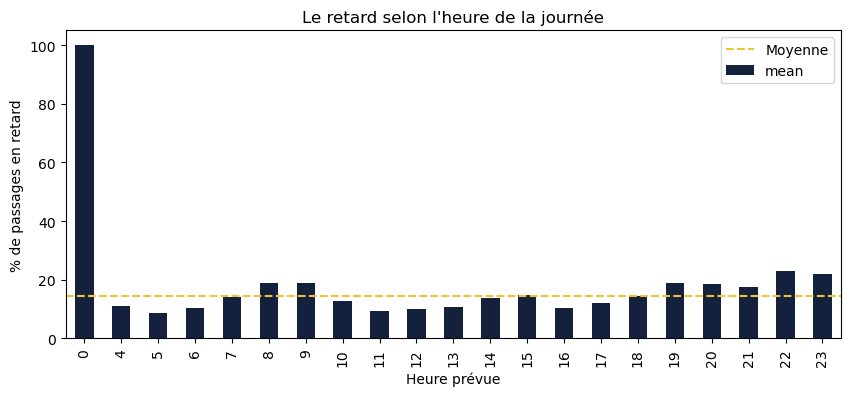

,mean,count
heure,,
0,100.0,1
4,10.9,64
5,8.6,984
6,10.5,3545
7,14.2,5216
8,18.8,5354
9,19.0,3530
10,12.6,1940
11,9.4,2404


In [12]:
import matplotlib.pyplot as plt

par_heure = df_ter.groupby("heure")["en_retard"].agg(["mean", "count"])
par_heure["mean"] = par_heure["mean"] * 100

par_heure["mean"].plot(kind="bar", figsize=(10, 4), color="#14213D")
plt.axhline(df_ter["en_retard"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages en retard")
plt.xlabel("Heure prévue")
plt.title("Le retard selon l'heure de la journée")
plt.legend()
plt.show()

par_heure.round(1)

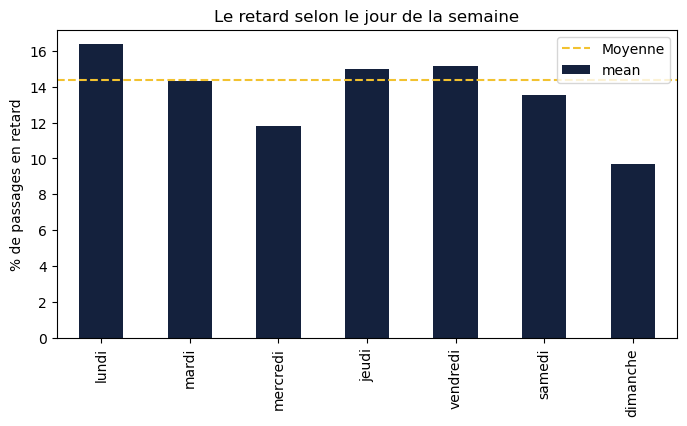

,mean,count
lundi,16.4,7458
mardi,14.3,10166
mercredi,11.8,10174
jeudi,15.0,10604
vendredi,15.1,18441
samedi,13.5,7544
dimanche,9.7,825


In [13]:
noms = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

par_jour = df_ter.groupby("jour_semaine")["en_retard"].agg(["mean", "count"])
par_jour["mean"] = par_jour["mean"] * 100
par_jour.index = noms

par_jour["mean"].plot(kind="bar", figsize=(8, 4), color="#14213D")
plt.axhline(df_ter["en_retard"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages en retard")
plt.title("Le retard selon le jour de la semaine")
plt.legend()
plt.show()

par_jour.round(1)

In [14]:
print(df_ter.groupby("jour_semaine")["date"].nunique())

par_date = df_ter.groupby("date")["en_retard"].mean() * 100
par_date.round(1)

jour_semaine
0    1
1    1
2    1
3    2
4    2
5    2
6    1
Name: date, dtype: int64


date
2026-10-08    22.2
2026-10-09    14.8
2026-10-10     9.7
2026-10-11     9.7
2026-10-12    16.4
2026-10-13    14.3
2026-10-14    11.8
2026-10-15    14.7
2026-10-16    15.4
2026-10-17    15.6
Name: en_retard, dtype: float64

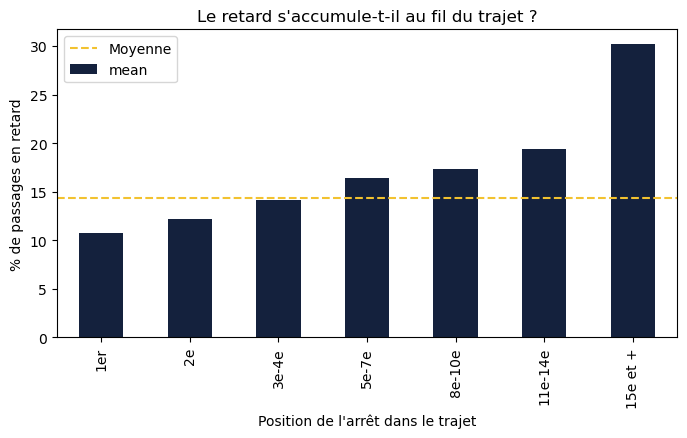

In [19]:
tranches=[0, 1, 2, 4, 7, 10, 14, 100]
nom_tranches=["1er","2e", "3e-4e", "5e-7e", "8e-10e", "11e-14e", "15e et +"]
df_ter['position']=pd.cut(df_ter['ordre_arret'],bins=tranches,labels=nom_tranches)
par_position=df_ter.groupby('position',observed=True)["en_retard"].agg(['mean','count'])
par_position["mean"] = par_position["mean"] * 100

par_position["mean"].plot(kind="bar", figsize=(8, 4), color="#14213D")
plt.axhline(df_ter["en_retard"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages en retard")
plt.xlabel("Position de l'arrêt dans le trajet")
plt.title("Le retard s'accumule-t-il au fil du trajet ?")
plt.legend()
plt.show()

In [20]:
par_position.round(1)

,mean,count
position,,
1er,10.7,7629
2e,12.2,7863
3e-4e,14.1,14584
5e-7e,16.5,16015
8e-10e,17.4,7743
11e-14e,19.4,3520
15e et +,30.2,712


In [21]:
print(df_ter["ordre_arret"].min(), df_ter["ordre_arret"].max())
print(df_ter["ordre_arret"].isna().sum())
print((df_ter["ordre_arret"] == 0).sum())

0.0 21.0
0
7146


Passages rangés : 65212 sur 65212


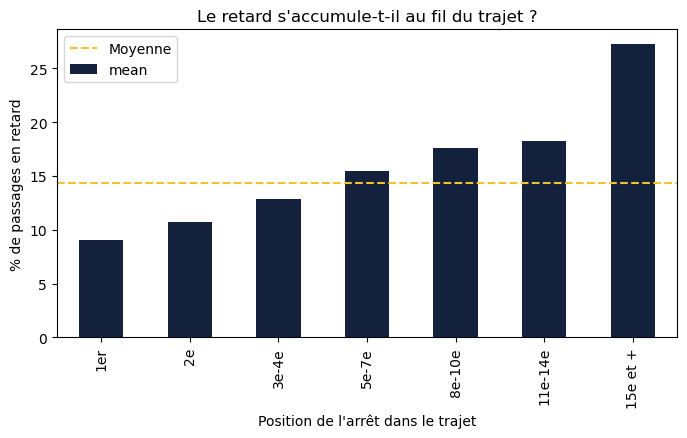

,mean,count
position,,
1er,9.0,7146
2e,10.7,7629
3e-4e,12.9,15471
5e-7e,15.5,18719
8e-10e,17.6,10147
11e-14e,18.2,4970
15e et +,27.3,1130


In [22]:
df_ter["rang"] = df_ter["ordre_arret"] + 1

tranches = [0, 1, 2, 4, 7, 10, 14, 100]
noms_tranches = ["1er", "2e", "3e-4e", "5e-7e", "8e-10e", "11e-14e", "15e et +"]
df_ter["position"] = pd.cut(df_ter["rang"], bins=tranches, labels=noms_tranches)

par_position = df_ter.groupby("position", observed=True)["en_retard"].agg(["mean", "count"])
par_position["mean"] = par_position["mean"] * 100
print("Passages rangés :", par_position["count"].sum(), "sur", len(df_ter))

par_position["mean"].plot(kind="bar", figsize=(8, 4), color="#14213D")
plt.axhline(df_ter["en_retard"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
plt.ylabel("% de passages en retard")
plt.xlabel("Position de l'arrêt dans le trajet")
plt.title("Le retard s'accumule-t-il au fil du trajet ?")
plt.legend()
plt.show()

par_position.round(1)

In [33]:
#le retard par rapport à la lignes 
par_ligne=df_ter.groupby('ligne')['en_retard'].agg(['mean','count'])
par_ligne['mean']=par_ligne['mean']*100
par_ligne=par_ligne[par_ligne['count']>=500].sort_values('mean',ascending=False)
print(len(par_ligne))
par_ligne.round(1)

46


,mean,count
ligne,,
K16,31.7,720
K40,29.1,1186
C40,26.3,2730
K44,22.2,860
P54,21.9,1706
C10,21.1,919
P23,19.7,1394
C14,19.5,1210
P44,18.4,993


In [38]:
df_ter['famille']=df_ter['ligne'].str[0]
print(df_ter.groupby('famille')['en_retard'].agg(['mean','count']).round(1))
etreme=df_ter[df_ter['ligne'].isin(["K16", "K40","K21","K11", "C40", "P72", "C76", "P43"])]
etreme.groupby('ligne')['nom_ligne'].first()

         mean  count
famille             
C         0.2  19039
K         0.2  19635
P         0.1  26538


ligne
C40         Lille Flandres - Douai
C76                   REIMS - LAON
K11    Paris Nord -Longueau-Amiens
K16                   Calais Paris
K21         Calais -Ville - Amiens
K40    Lille Flandres - St Quentin
P43           Douai - Valenciennes
P72       Calais Ville - Dunkerque
Name: nom_ligne, dtype: object

In [39]:
(df_ter.groupby("famille")["en_retard"].mean() * 100).round(1)

famille
C    16.3
K    15.5
P    12.1
Name: en_retard, dtype: float64

In [53]:
#Analyse par rapport à la meteo
passage_sans_plui=df_ter['pluie_mm'].isna().mean()*100
print(passage_sans_plui)
meteo=df_ter.dropna(subset=["pluie_mm", "rafales_kmh"]).copy()
meteo['pluie']=pd.cut(meteo['pluie_mm'],bins=[-1, 0, 0.5, 2, 100],labels=["sec", "bruine", "pluie", "forte pluie"])
meteo['vent']=pd.cut(meteo['rafales_kmh'],bins=[-1, 30, 50, 70, 200],labels=["calme", "modéré", "fort", "très fort"])
print((meteo.groupby("pluie", observed=True)["en_retard"].agg(["mean", "count"]) * [100, 1]).round(1))
print((meteo.groupby("vent", observed=True)["en_retard"].agg(["mean", "count"]) * [100, 1]).round(1))

0.23615285530270502
             mean  count
pluie                   
sec          14.2  55460
bruine       15.5   7274
pluie        14.2   1951
forte pluie  22.5    373
           mean  count
vent                  
calme      14.2  46353
modéré     14.8  16991
fort       15.0   1479
très fort  14.0    235


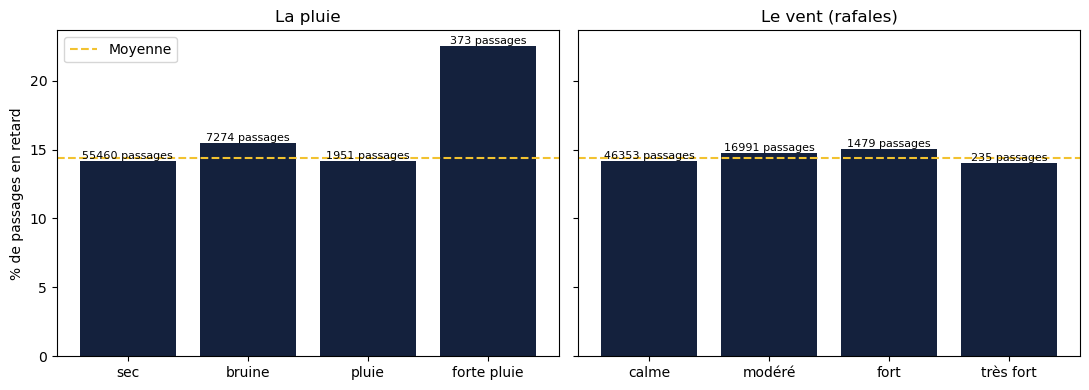

In [54]:
taux_pluie = meteo.groupby("pluie", observed=True)["en_retard"].agg(["mean", "count"])
taux_vent = meteo.groupby("vent", observed=True)["en_retard"].agg(["mean", "count"])

fig, (gauche, droite) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for axe, taux, titre in [(gauche, taux_pluie, "La pluie"), (droite, taux_vent, "Le vent (rafales)")]:
    barres = axe.bar(taux.index.astype(str), taux["mean"] * 100, color="#14213D")
    axe.axhline(meteo["en_retard"].mean() * 100, color="#F2C230", linestyle="--", label="Moyenne")
    axe.bar_label(barres, labels=[f"{n} passages" for n in taux["count"]], fontsize=8)
    axe.set_title(titre)

gauche.set_ylabel("% de passages en retard")
gauche.legend()
plt.tight_layout()
plt.show()